##Set Up and Test the Connection

In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

r = requests.get("https://books.toscrape.com/catalogue/page-1.html")
print(r.status_code)

200


## Step 2: Reconnaissance
Inspecting the HTML to find where title, price, rating and availability are stored.

In [2]:
soup = BeautifulSoup(r.text, "html.parser")
first_book = soup.find("article", class_="product_pod")
print(first_book.prettify())

<article class="product_pod">
 <div class="image_container">
  <a href="a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="../media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="a-light-in-the-attic_1000/index.html" title="A Light in the Attic">
   A Light in the ...
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   Â£51.77
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



**TABLE**

## Mission 1: Reconnaissance

| Data Needed | HTML Tag / Class Found | Notes |
|---|---|---|
| Book Title | h3 > a (title attribute) | Visible text is cut off, so use the title attribute |
| Price | p.price_color | Shows Â£ due to encoding, fix with UTF-8 and strip £ |
| Rating | p.star-rating + word class | Rating is a word (One to Five), convert to 1 to 5 |
| Availability | p.instock.availability | Has extra spaces, use .strip() |

##Step 2: Reconnaissance (final check)

In [3]:
books = soup.find_all("article", class_="product_pod")
print(len(books))

20


## Step 3: Capture the Data (Page 1)
Extracting title, price, rating and availability from the first page.

In [4]:
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

url = "https://books.toscrape.com/catalogue/page-1.html"
response = requests.get(url)
response.encoding = "utf-8"          # fixes the Â£ problem
soup = BeautifulSoup(response.text, "html.parser")

page1_books = []

for book in soup.find_all("article", class_="product_pod"):
    title = book.h3.a["title"]
    price = float(book.find("p", class_="price_color").text.replace("£", ""))
    rating_word = book.find("p", class_="star-rating")["class"][1]
    rating = rating_map[rating_word]
    availability = book.find("p", class_="instock availability").text.strip()

    page1_books.append({
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability
    })

df_page1 = pd.DataFrame(page1_books)
df_page1.head()

,Title,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock


## Step 4: Scale the Operation
Turning the scraper into a reusable function and looping over 5 pages.
Also saving each book's product page URL (Bonus 2).

In [5]:
from urllib.parse import urljoin

def scrape_page(url):
    response = requests.get(url)
    response.encoding = "utf-8"
    soup = BeautifulSoup(response.text, "html.parser")

    books = []
    for book in soup.find_all("article", class_="product_pod"):
        books.append({
            "Title": book.h3.a["title"],
            "Price": float(book.find("p", class_="price_color").text.replace("£", "")),
            "Rating": rating_map[book.find("p", class_="star-rating")["class"][1]],
            "Availability": book.find("p", class_="instock availability").text.strip(),
            "URL": urljoin(url, book.h3.a["href"])
        })
    return books


all_books = []
for page in range(1, 6):   # pages 1 to 5
    url = f"https://books.toscrape.com/catalogue/page-{page}.html"
    page_books = scrape_page(url)
    all_books.extend(page_books)
    print(f"Page {page}: {len(page_books)} books")

df = pd.DataFrame(all_books)
df.to_csv("competitor_books.csv", index=False)

print("\nTotal books:", len(df))
print(df.dtypes)
df.head()

Page 1: 20 books
Page 2: 20 books
Page 3: 20 books
Page 4: 20 books
Page 5: 20 books

Total books: 100
Title            object
Price           float64
Rating            int64
Availability     object
URL              object
dtype: object


,Title,Price,Rating,Availability,URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [6]:
from google.colab import files
files.download("competitor_books.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 5: Intelligence Analysis
Answering the manager's 7 business questions using the DataFrame.

In [7]:
# 1. Most expensive
most_exp = df.loc[df["Price"].idxmax()]
print("1. Most expensive:", most_exp["Title"], "| £", most_exp["Price"])

# 2. Cheapest
cheapest = df.loc[df["Price"].idxmin()]
print("2. Cheapest:", cheapest["Title"], "| £", cheapest["Price"])

# 3. Average price
print("3. Average price: £", round(df["Price"].mean(), 2))

# 4. Number of 5-star books
five_star = df[df["Rating"] == 5]
print("4. Books with 5 stars:", len(five_star))

# 5. Percentage in stock
in_stock = (df["Availability"] == "In stock").mean() * 100
print("5. In stock:", round(in_stock, 1), "%")

# 6. Top 5 highest-rated (ties broken by lower price)
top5 = df.sort_values(["Rating", "Price"], ascending=[False, True]).head(5)
print("6. Top 5 highest-rated books:")
print(top5[["Title", "Price", "Rating"]].to_string(index=False))

# 7. Cheapest 5-star book
cheap5 = five_star.loc[five_star["Price"].idxmin()]
print("7. Cheapest 5-star book:", cheap5["Title"], "| £", cheap5["Price"])

1. Most expensive: The Death of Humanity: and the Case for Life | £ 58.11
2. Cheapest: Patience | £ 10.16
3. Average price: £ 34.56
4. Books with 5 stars: 19
5. In stock: 100.0 %
6. Top 5 highest-rated books:
                                                                            Title  Price  Rating
                                 Princess Between Worlds (Wide-Awake Princess #5)  13.34       5
Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Princess Jellyfish 2-in-1 Omnibus #1)  13.61       5
                                                                   Sophie's World  15.94       5
                                                                           Thirst  17.27       5
                                                                      Set Me Free  17.46       5
7. Cheapest 5-star book: Princess Between Worlds (Wide-Awake Princess #5) | £ 13.34


## Step 6: CEO £100 Challenge
Choosing books that maximise total star rating without spending more than £100.
I used the 0/1 knapsack method, which checks every combination for the best one,
and compared it with a simple greedy approach.

In [8]:
budget = 10000                                  # £100 in pence
costs = (df["Price"] * 100).round().astype(int).tolist()
stars = df["Rating"].tolist()

# best[b] = most stars possible with budget b
best = [0] * (budget + 1)
chosen = [[] for _ in range(budget + 1)]

for i in range(len(df)):
    for b in range(budget, costs[i] - 1, -1):
        if best[b - costs[i]] + stars[i] > best[b]:
            best[b] = best[b - costs[i]] + stars[i]
            chosen[b] = chosen[b - costs[i]] + [i]

picks = df.loc[chosen[budget], ["Title", "Price", "Rating"]]
print("OPTIMAL (knapsack):")
print(picks.to_string(index=False))
print("Books:", len(picks), "| Total cost: £", round(picks["Price"].sum(), 2),
      "| Total stars:", picks["Rating"].sum())

# Greedy comparison: cheapest 5-star books first
greedy, spent = [], 0
for _, row in df.sort_values(["Rating", "Price"], ascending=[False, True]).iterrows():
    if spent + row["Price"] <= 100:
        greedy.append(row)
        spent += row["Price"]
greedy = pd.DataFrame(greedy)
print("\nGREEDY (cheapest 5-stars first):")
print("Books:", len(greedy), "| Total cost: £", round(spent, 2),
      "| Total stars:", greedy["Rating"].sum())

OPTIMAL (knapsack):
                                                                              Title  Price  Rating
                                                                        Set Me Free  17.46       5
                                                                     Sophie's World  15.94       5
                                            Untitled Collection: Sabbath Poems 2014  14.27       4
  Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Princess Jellyfish 2-in-1 Omnibus #1)  13.61       5
                                   Princess Between Worlds (Wide-Awake Princess #5)  13.34       5
                                                                           Patience  10.16       3
Mama Tried: Traditional Italian Cooking for the Screwed, Crude, Vegan, and Tattooed  14.02       4
Books: 7 | Total cost: £ 98.8 | Total stars: 31

GREEDY (cheapest 5-stars first):
Books: 6 | Total cost: £ 95.28 | Total stars: 30


## Step 7: Bonus Missions
Bonus 3: counting books at each star-rating level.
Bonus 4: bar chart of rating counts.

Books per rating:
Rating
1    22
2    19
3    22
4    18
5    19

Average price per rating:
Rating
1    35.52
2    35.91
3    36.84
4    33.98
5    30.01


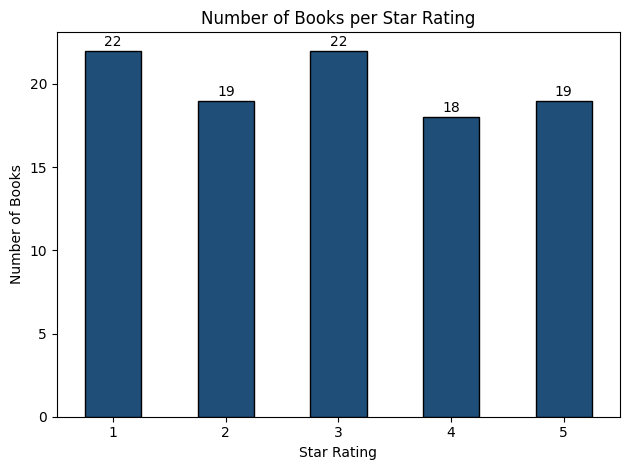

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import matplotlib.pyplot as plt

# Bonus 3: count per rating
rating_counts = df["Rating"].value_counts().sort_index()
print("Books per rating:")
print(rating_counts.to_string())

# Average price per rating (useful for the business decision)
print("\nAverage price per rating:")
print(df.groupby("Rating")["Price"].mean().round(2).to_string())

# Bonus 4: bar chart
ax = rating_counts.plot(kind="bar", color="#1F4E79", edgecolor="black")
ax.set_title("Number of Books per Star Rating")
ax.set_xlabel("Star Rating")
ax.set_ylabel("Number of Books")
for i, v in enumerate(rating_counts):
    ax.text(i, v + 0.3, str(v), ha="center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("rating_counts.png", dpi=150)
plt.show()

files.download("rating_counts.png")

## Business Recommendation
If I were launching a competing online bookstore, I would prioritise the competitor's
5-star books, especially the cheaper ones like Princess Between Worlds (£13.34),
Sophie's World (£15.94) and Set Me Free (£17.46). Only 19 of the 100 books have 5 stars,
but they average just £30.01 compared to £34.56 across all books, so they give customers
the best quality for the price. Since every scraped book is in stock, I can't win on
availability, so I would compete by matching or slightly undercutting prices on these
top-rated titles.